# Cancer Data Analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [2]:
data = pd.read_csv('global_cancer_patients_2015_2024.csv')
data

,Patient_ID,Age,Gender,Country_Region,Year,Genetic_Risk,Air_Pollution,Alcohol_Use,Smoking,Obesity_Level,Cancer_Type,Cancer_Stage,Treatment_Cost_USD,Survival_Years,Target_Severity_Score
0,PT0000000,71,Male,UK,2021,6.4,2.8,9.5,0.9,8.7,Lung,Stage III,62913.44,5.9,4.92
1,PT0000001,34,Male,China,2021,1.3,4.5,3.7,3.9,6.3,Leukemia,Stage 0,12573.41,4.7,4.65
2,PT0000002,80,Male,Pakistan,2023,7.4,7.9,2.4,4.7,0.1,Breast,Stage II,6984.33,7.1,5.84
3,PT0000003,40,Male,UK,2015,1.7,2.9,4.8,3.5,2.7,Colon,Stage I,67446.25,1.6,3.12
4,PT0000004,43,Female,Brazil,2017,5.1,2.8,2.3,6.7,0.5,Skin,Stage III,77977.12,2.9,3.62
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,PT0049995,80,Male,Pakistan,2023,2.3,7.5,2.8,3.8,2.9,Leukemia,Stage 0,71463.70,1.0,3.63
49996,PT0049996,40,Female,USA,2018,6.4,3.5,2.9,9.0,9.8,Colon,Stage I,49619.66,0.4,6.03
49997,PT0049997,74,Male,Pakistan,2015,6.2,1.6,8.7,4.7,4.0,Breast,Stage 0,5338.25,2.7,6.02
49998,PT0049998,21,Male,Brazil,2018,4.0,6.5,7.6,8.6,8.1,Liver,Stage IV,45100.47,7.5,6.54


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Patient_ID             50000 non-null  object 
 1   Age                    50000 non-null  int64  
 2   Gender                 50000 non-null  object 
 3   Country_Region         50000 non-null  object 
 4   Year                   50000 non-null  int64  
 5   Genetic_Risk           50000 non-null  float64
 6   Air_Pollution          50000 non-null  float64
 7   Alcohol_Use            50000 non-null  float64
 8   Smoking                50000 non-null  float64
 9   Obesity_Level          50000 non-null  float64
 10  Cancer_Type            50000 non-null  object 
 11  Cancer_Stage           50000 non-null  object 
 12  Treatment_Cost_USD     50000 non-null  float64
 13  Survival_Years         50000 non-null  float64
 14  Target_Severity_Score  50000 non-null  float64
dtypes:

In [4]:
data.duplicated().sum()

np.int64(0)

## Descriptive Analysis

### Age Column

<function matplotlib.pyplot.show(close=None, block=None)>

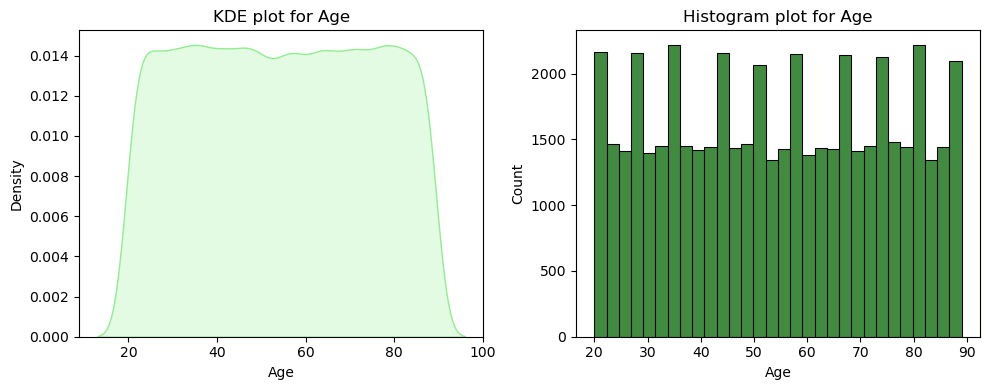

In [5]:
plt.figure(figsize=(10, 4))

plt.subplot(1,2,1)
sns.kdeplot(data["Age"], fill=True, color='lightgreen')
plt.title("KDE plot for Age")

plt.subplot(1,2,2)
sns.histplot(data["Age"], bins=30, kde=False, color='darkgreen')
plt.title("Histogram plot for Age")

plt.tight_layout()
plt.show

In [6]:
data["Age"].describe()

count    50000.000000
mean        54.421540
std         20.224451
min         20.000000
25%         37.000000
50%         54.000000
75%         72.000000
max         89.000000
Name: Age, dtype: float64

### Gender Column

In [64]:
data["Gender"].value_counts()

Gender
1    16796
0    16709
2    16495
Name: count, dtype: int64

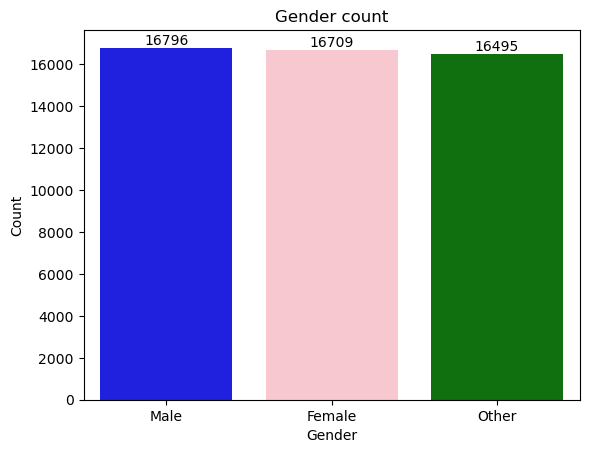

In [8]:
sns.barplot(
    x=data["Gender"].value_counts().index,
    y=data["Gender"].value_counts().values,
    palette=["blue", "pink", "green"]
)
for i , v in enumerate(data["Gender"].value_counts()):
    plt.text(i,v, str(v), ha="center", va="bottom")

plt.title("Gender count")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

### Countries Column

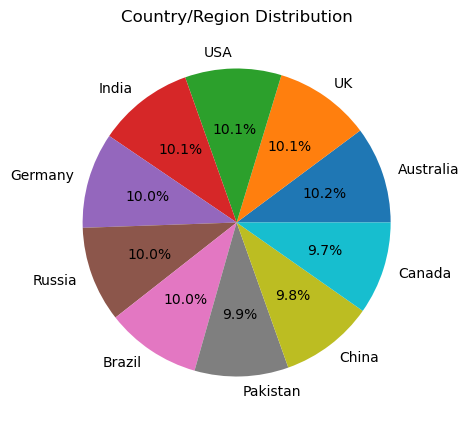

In [9]:
country_counts= data["Country_Region"].value_counts()

plt.figure(figsize=(5,5))
plt.pie(x=country_counts.values, 
        labels=country_counts.index,
        autopct= '%1.1f%%'
       )

plt.title("Country/Region Distribution")
plt.show()

### Cancer Type

In [10]:
data["Cancer_Type"].value_counts()

Cancer_Type
Colon       6376
Prostate    6308
Leukemia    6266
Liver       6249
Skin        6231
Cervical    6222
Breast      6189
Lung        6159
Name: count, dtype: int64

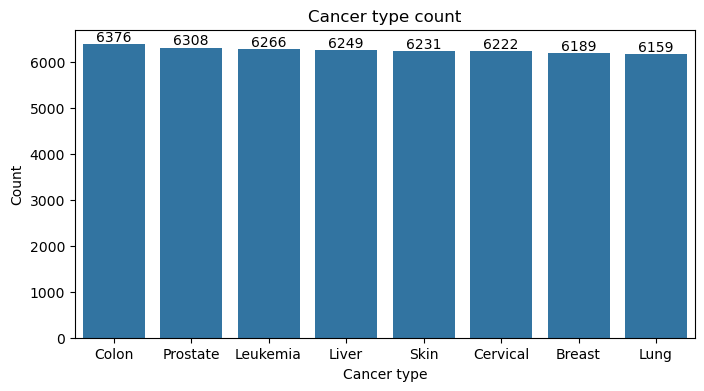

In [11]:
plt.figure(figsize=(8, 4))
sns.barplot(x=data["Cancer_Type"].value_counts().index,
            y=data["Cancer_Type"].value_counts().values)

for i , v  in enumerate(data["Cancer_Type"].value_counts()):
    plt.text(i,v, str(v), ha="center", va="bottom")

plt.title("Cancer type count")
plt.xlabel("Cancer type")
plt.ylabel("Count")
plt.show()

### Cancer Stage

In [12]:
data["Cancer_Stage"].value_counts()

Cancer_Stage
Stage II     10124
Stage I      10046
Stage III    10008
Stage IV      9933
Stage 0       9889
Name: count, dtype: int64

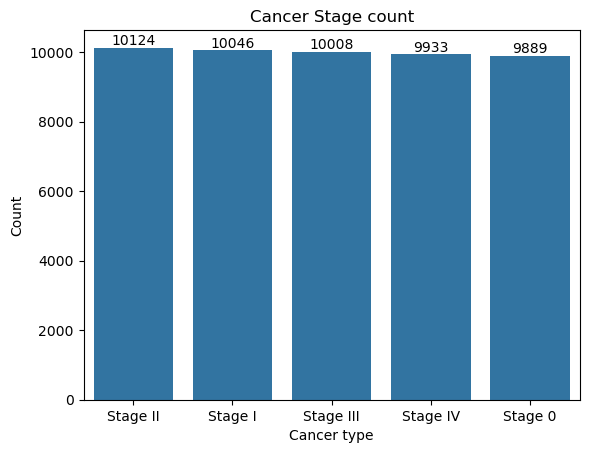

In [13]:
sns.barplot(x=data["Cancer_Stage"].value_counts().index,
            y=data["Cancer_Stage"].value_counts().values)

for i , v  in enumerate(data["Cancer_Stage"].value_counts()):
    plt.text(i,v, str(v), ha="center", va="bottom")

plt.title("Cancer Stage count")
plt.xlabel("Cancer type")
plt.ylabel("Count")
plt.show()

### Treatment Cost

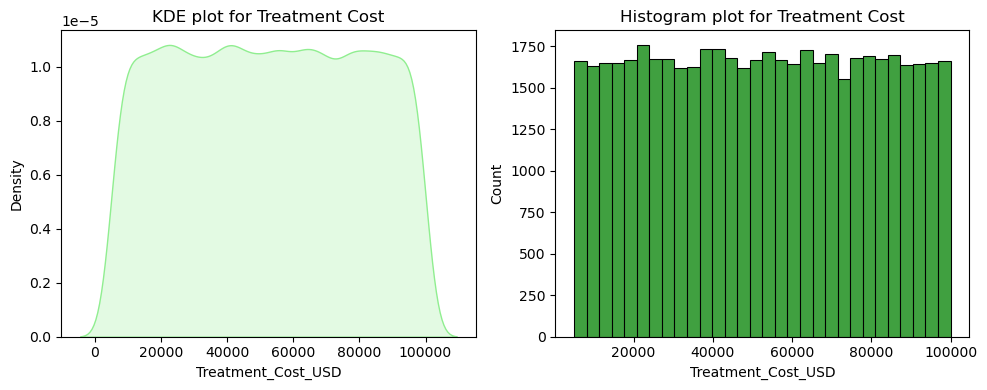

In [14]:
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
sns.kdeplot(data["Treatment_Cost_USD"], fill=True, color="lightgreen")
plt.title("KDE plot for Treatment Cost")

plt.subplot(1,2,2)
sns.histplot(data["Treatment_Cost_USD"], bins=30,  kde=False, color="green")
plt.title("Histogram plot for Treatment Cost")

plt.tight_layout()
plt.show()

In [15]:
data["Treatment_Cost_USD"].describe()

count    50000.000000
mean     52467.298239
std      27363.229379
min       5000.050000
25%      28686.225000
50%      52474.310000
75%      76232.720000
max      99999.840000
Name: Treatment_Cost_USD, dtype: float64

## ANALYLIZING THE RISK FACTORS

In [16]:
risk_factors= ['Genetic_Risk','Air_Pollution', 'Alcohol_Use', 'Smoking', 'Obesity_Level']

summary= data[risk_factors].agg(['mean', "std", "min", "max"])
summary.T

,mean,std,min,max
Genetic_Risk,5.001698,2.885773,0.0,10.0
Air_Pollution,5.010126,2.888399,0.0,10.0
Alcohol_Use,5.010880,2.888769,0.0,10.0
Smoking,4.989826,2.881579,0.0,10.0
Obesity_Level,4.991176,2.894504,0.0,10.0


## Determine the relationship between risk factors and cancer severity

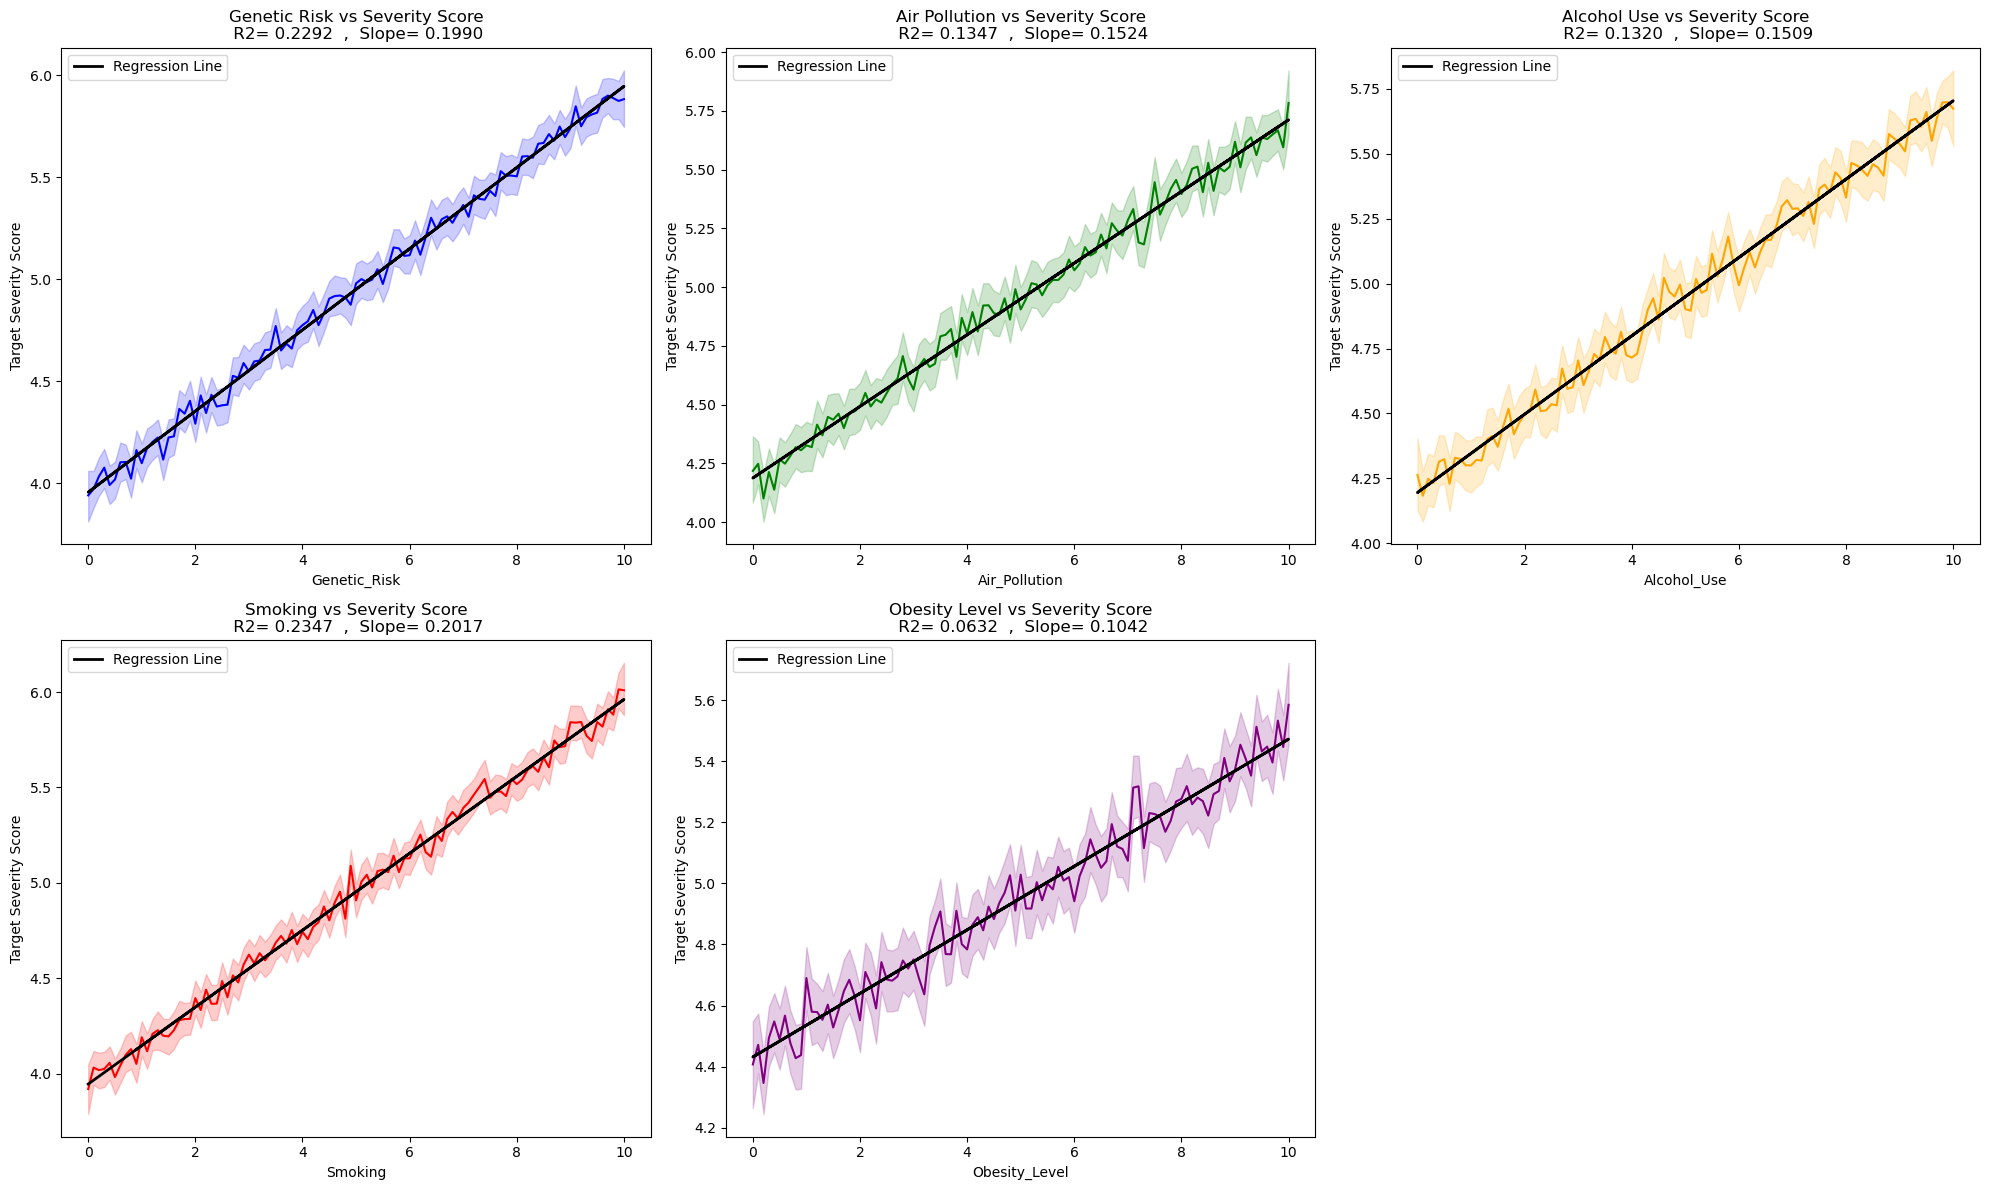

In [17]:
from scipy.stats import linregress

risk_factors= ['Genetic_Risk','Air_Pollution', 'Alcohol_Use', 'Smoking', 'Obesity_Level']
titles= ['Genetic Risk','Air Pollution', 'Alcohol Use', 'Smoking', 'Obesity Level']
colors= ["blue", "green", "orange", "red", "purple"]

plt.figure(figsize=(20,12))

for i , (factor , title,color) in enumerate(zip(risk_factors, titles, colors),1):
    plt.subplot(2,3,i)
    
    x=data[factor]
    y=data["Target_Severity_Score"]
    slope, intercept , r_value , p_value , std_err= linregress(x,y)
    r_squared= r_value**2

    sns.lineplot(x=factor, y="Target_Severity_Score", data=data, color=color)
    plt.plot(x,x*slope+intercept, color="black", linewidth=2, label="Regression Line")
    plt.title(f"{title} vs Severity Score\n R2= {r_squared:.4f}  ,  Slope= {slope:.4f}")
    plt.xlabel(factor)
    plt.ylabel("Target Severity Score")
    plt.legend()

#line= y=mx+c

plt.tight_layout()
plt.show()

## Analyze the proportion of early-stage diagnoses by cancer type

In [18]:
data["Cancer_Type"].unique()

array(['Lung', 'Leukemia', 'Breast', 'Colon', 'Skin', 'Cervical',
       'Prostate', 'Liver'], dtype=object)

In [19]:
cancer_types = [
    "Lung",
    "Leukemia",
    "Breast",
    "Skin",
    "Colon",
    "Prostate",
    "Cervical",
    "Liver"
]

cancer_proportions = {}

for cancer in cancer_types:

    stage_count = data[data["Cancer_Type"] == cancer]["Cancer_Stage"].value_counts()

    early_stage_sum = (
        stage_count.get("Stage 0", 0) +
        stage_count.get("Stage I", 0)
    )

    total_sum = stage_count.sum()

    proportion = (early_stage_sum / total_sum) * 100 if total_sum > 0 else 0

    cancer_proportions[cancer] = proportion

print(cancer_proportions)

{'Lung': np.float64(38.43156356551388), 'Leukemia': np.float64(39.53080114905841), 'Breast': np.float64(39.47325900791727), 'Skin': np.float64(40.41084898090194), 'Colon': np.float64(40.41718946047679), 'Prostate': np.float64(40.187064045656314), 'Cervical': np.float64(39.85856637737062), 'Liver': np.float64(40.614498319731155)}


In [20]:
plot_data = pd.DataFrame(
    list(cancer_proportions.items()),
    columns=["Cancer_Type", "Early_Stage_Percentage"]
)
plot_data = plot_data.sort_values(
    by="Early_Stage_Percentage",
    ascending=False
).reset_index(drop=True)

plot_data

,Cancer_Type,Early_Stage_Percentage
0,Liver,40.614498
1,Colon,40.417189
2,Skin,40.410849
3,Prostate,40.187064
4,Cervical,39.858566
5,Leukemia,39.530801
6,Breast,39.473259
7,Lung,38.431564


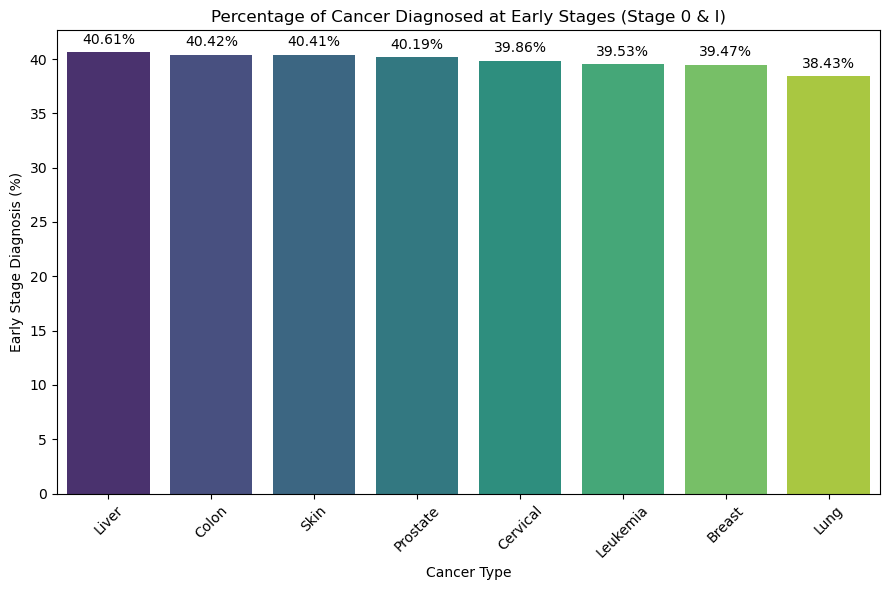

In [21]:
plt.figure(figsize=(9, 6))

ax = sns.barplot(
    data=plot_data,
    x="Cancer_Type",
    y="Early_Stage_Percentage",
    hue="Cancer_Type",
    palette="viridis",
    legend=False
)

# Add percentage labels above each bar
for i, v in enumerate(plot_data["Early_Stage_Percentage"]):
    ax.text(i, v + 0.5, f"{v:.2f}%", ha="center", va="bottom")

plt.title("Percentage of Cancer Diagnosed at Early Stages (Stage 0 & I)")
plt.xlabel("Cancer Type")
plt.ylabel("Early Stage Diagnosis (%)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Identify key predictors of cancer severity and survival years

In [ ]:
features= ["Age", 'Genetic_Risk','Air_Pollution', 'Alcohol_Use', 'Smoking', 'Obesity_Level']

targets= ["Survival_Years","Target_Severity_Score"]

#calculate correlations
pearson_corr= data[features+targets].corr(method="pearson")
spearman_corr= data[features+targets].corr(method="spearman")

# slice out only thr relationship with target variables
pearson_results= pearson_corr[targets]
spearman_results=spearman_corr[targets]

#combine both
correlation_df= pd.concat([pearson_results,spearman_results], axis=1, keys=["Pearson","Spearman"])
correlation_df

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Pearson correlation
sns.heatmap(
    pearson_results.loc[features],
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    center=0,
    linewidths=0.5,
    ax=axes[0]
)

axes[0].set_title("Pearson Correlation with Target Variables")

# Spearman correlation
sns.heatmap(
    spearman_results.loc[features],
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    center=0,
    linewidths=0.5,
    ax=axes[1]
)

axes[1].set_title("Spearman Correlation with Target Variables")

plt.tight_layout()
plt.show()


## 1. Correlation with Cancer Severity Score

| Feature | Pearson Correlation | Spearman Correlation | Interpretation |
|:---|---:|---:|:---|
| Smoking | 0.484 | 0.478 | Moderate positive correlation. Higher smoking levels are associated with higher cancer severity scores. |
| Genetic_Risk | 0.479 | 0.472 | Moderate positive correlation. Genetic risk shows a positive association with cancer severity. |
| Air_Pollution | 0.367 | 0.358 | Moderate positive correlation. Higher air pollution exposure is associated with higher severity scores. |
| Alcohol_Use | 0.363 | 0.355 | Moderate positive correlation. Alcohol consumption is positively associated with cancer severity. |
| Obesity_Level | 0.251 | 0.243 | Weak positive correlation. Obesity has a relatively weaker association with cancer severity. |
| Age | -0.001481 | -0.002076 | Negligible correlation. Age shows almost no relationship with cancer severity. |

### Key Findings
- Smoking has the highest positive correlation with cancer severity (Pearson: 0.484).
- Genetic_Risk is the second strongest correlated feature (Pearson: 0.479).
- Air_Pollution and Alcohol_Use also show moderate positive correlations.
- Age shows almost no correlation with cancer severity.

---

## 2. Correlation with Survival Years

| Feature | Pearson Correlation | Spearman Correlation | Interpretation |
|:---|---:|---:|:---|
| Age | -0.000147 | -0.000149 | Negligible correlation. Age shows almost no association with survival duration. |
| Genetic_Risk | 0.001708 | 0.001684 | Negligible correlation. Genetic risk shows almost no association with survival years. |
| Air_Pollution | 0.000893 | 0.000841 | Negligible correlation. Air pollution has almost no observed correlation with survival duration. |
| Alcohol_Use | -0.000527 | -0.000543 | Negligible correlation. Alcohol use shows almost no observed correlation with survival years. |
| Smoking | 0.001371 | 0.001372 | Negligible correlation. Smoking has almost no observed correlation with survival duration. |
| Obesity_Level | 0.009771 | 0.009780 | Negligible correlation. Obesity level shows almost no association with survival years. |
| Target_Severity_Score | 0.004161 | 0.003431 | Negligible correlation. Cancer severity score shows almost no observed correlation with survival duration. |

### Key Findings
- All examined features have correlation coefficients very close to zero with Survival_Years.
- Target_Severity_Score also shows negligible correlation with survival duration.
- Both Pearson and Spearman correlation methods produce similar results.

---

## 3. Overall EDA Insights

| Analysis | Observation |
|:---|:---|
| Highest severity correlation | Smoking (0.484) |
| Second highest severity correlation | Genetic_Risk (0.479) |
| Environmental factor | Air_Pollution (0.367) |
| Lowest severity correlation | Age (-0.001481) |
| Survival Years | All examined correlations are approximately zero. |

### Conclusion

The correlation analysis indicates that Smoking and Genetic_Risk have the strongest positive associations with Cancer Severity Score, followed by Air_Pollution and Alcohol_Use.

However, all examined features show negligible individual correlations with Survival_Years. This suggests that the relationship between these features and survival duration may not be captured by simple linear or monotonic correlation.

**Note:** Correlation does not imply causation. Further statistical analysis and machine learning models may help identify more complex relationships between the features and target variables.


In [ ]:
# random forest for target severity score
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import r2_score

# caonveting categorical columns to numerical columns
categorical_cols= ["Gender","Country_Region","Cancer_Type","Cancer_Stage"]
for col in categorical_cols:
    le= LabelEncoder()
    data[col]=le.fit_transform(data[col])

# Preparing  features and input
X= data.drop(columns=["Patient_ID","Survival_Years","Target_Severity_Score"])
y_severity= data["Target_Severity_Score"]

# train test split
X_train_s, X_test_s, y_train_s, y_test_s= train_test_split(X, y_severity, test_size=0.2, random_state=40)

# train the model
model= RandomForestRegressor(n_estimators=300, max_depth= None , min_samples_split=2,min_samples_leaf=1, random_state=40)
model.fit(X_train_s, y_train_s)

# evalaute the model
train_r2_severity= r2_score(y_train_s , model.predict(X_train_s))
test_r2_severity= r2_score(y_test_s , model.predict(X_test_s))

In [ ]:
print(train_r2_severity)
print(test_r2_severity)

In [ ]:
feature_importance_severity = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

# Plotting feature importance
plt.figure(figsize=(10, 5))

ax = feature_importance_severity.plot(
    kind="barh",
    color="skyblue"
)

# Add values to each bar
ax.bar_label(ax.containers[0], fmt="%.4f", padding=5)

plt.title("Feature Importance for Target Severity Score (Random Forest)")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.xlim(0,0.25)
plt.tight_layout()
plt.show()

In [22]:
# random forest for survival years
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import r2_score

# caonveting categorical columns to numerical columns
categorical_cols= ["Gender","Country_Region","Cancer_Type","Cancer_Stage"]
for col in categorical_cols:
    le= LabelEncoder()
    data[col]=le.fit_transform(data[col])

# Preparing  features and input
X= data.drop(columns=["Patient_ID","Survival_Years","Target_Severity_Score"])
y_survival= data["Survival_Years"]

# train test split
X_train_sur, X_test_sur, y_train_sur, y_test_sur = train_test_split(X, y_survival, test_size=0.2, random_state=40)

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [2]
}

# train the model
model= RandomForestRegressor(random_state=40)
GSC= GridSearchCV(model , param_grid, cv=2, scoring="r2", n_jobs=-1)
GSC.fit(X_train_sur, y_train_sur)

GridSearchCV(cv=2, estimator=RandomForestRegressor(random_state=40), n_jobs=-1,
             param_grid={'max_depth': [10, None], 'min_samples_leaf': [2],
                         'min_samples_split': [2, 5],
                         'n_estimators': [100, 200]},
             scoring='r2')

In [24]:
best_rf_survival = GSC.best_estimator_

# evalaute the model
train_r2_survival= r2_score(y_train_sur , best_rf_survival.predict(X_train_sur))
test_r2_survival= r2_score(y_test_sur , best_rf_survival.predict(X_test_sur))

In [25]:
print(train_r2_survival)
print(test_r2_survival)

0.0807442583646768
-0.0017626419715688346


<Axes: xlabel='Survival_Years', ylabel='Count'>

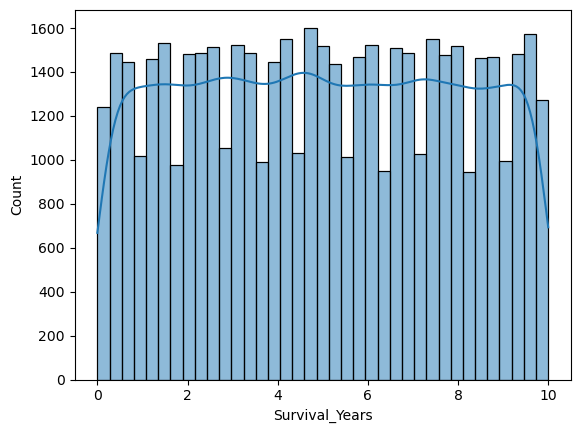

In [26]:
sns.histplot(data["Survival_Years"], kde=True)

In [27]:
data.corr(numeric_only=True)["Survival_Years"].sort_values(ascending=True)

Gender                  -0.007121
Cancer_Stage            -0.003014
Cancer_Type             -0.001717
Alcohol_Use             -0.000527
Treatment_Cost_USD      -0.000429
Age                     -0.000147
Year                     0.000018
Air_Pollution            0.000893
Smoking                  0.001371
Genetic_Risk             0.001708
Target_Severity_Score    0.004161
Country_Region           0.005121
Obesity_Level            0.009771
Survival_Years           1.000000
Name: Survival_Years, dtype: float64

## Explore the economic burden of cancer treatment across different demographics and countries

In [28]:
df = pd.read_csv("global_cancer_patients_2015_2024.csv")
df

,Patient_ID,Age,Gender,Country_Region,Year,Genetic_Risk,Air_Pollution,Alcohol_Use,Smoking,Obesity_Level,Cancer_Type,Cancer_Stage,Treatment_Cost_USD,Survival_Years,Target_Severity_Score
0,PT0000000,71,Male,UK,2021,6.4,2.8,9.5,0.9,8.7,Lung,Stage III,62913.44,5.9,4.92
1,PT0000001,34,Male,China,2021,1.3,4.5,3.7,3.9,6.3,Leukemia,Stage 0,12573.41,4.7,4.65
2,PT0000002,80,Male,Pakistan,2023,7.4,7.9,2.4,4.7,0.1,Breast,Stage II,6984.33,7.1,5.84
3,PT0000003,40,Male,UK,2015,1.7,2.9,4.8,3.5,2.7,Colon,Stage I,67446.25,1.6,3.12
4,PT0000004,43,Female,Brazil,2017,5.1,2.8,2.3,6.7,0.5,Skin,Stage III,77977.12,2.9,3.62
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,PT0049995,80,Male,Pakistan,2023,2.3,7.5,2.8,3.8,2.9,Leukemia,Stage 0,71463.70,1.0,3.63
49996,PT0049996,40,Female,USA,2018,6.4,3.5,2.9,9.0,9.8,Colon,Stage I,49619.66,0.4,6.03
49997,PT0049997,74,Male,Pakistan,2015,6.2,1.6,8.7,4.7,4.0,Breast,Stage 0,5338.25,2.7,6.02
49998,PT0049998,21,Male,Brazil,2018,4.0,6.5,7.6,8.6,8.1,Liver,Stage IV,45100.47,7.5,6.54


In [29]:
df["Age_Group"]=pd.cut(df["Age"],bins=[0,30,45,60,75,100],labels=["0-30","31-45","46-60","61-75","76+"])

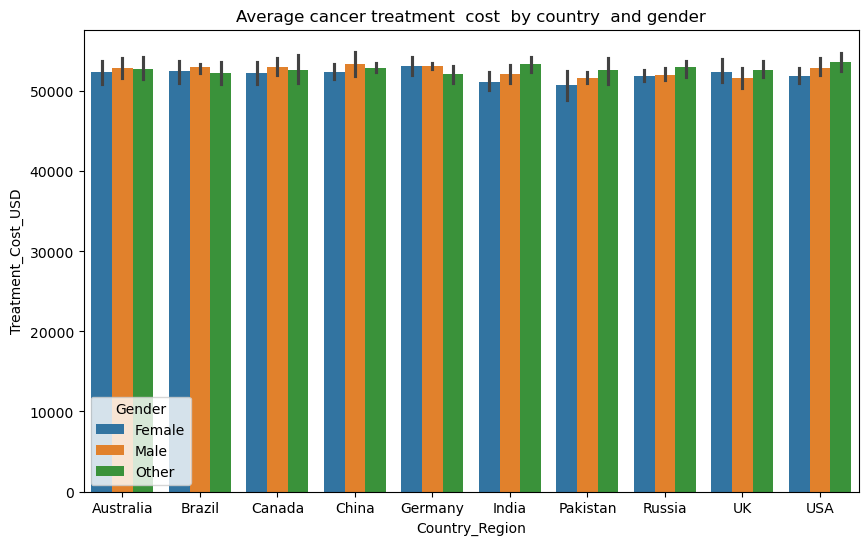

In [31]:
country_age_cost= df.groupby(["Country_Region", "Age_Group","Gender"])["Treatment_Cost_USD"].mean().reset_index()
plt.figure(figsize=(10,6))
sns.barplot(data=country_age_cost,x="Country_Region", y="Treatment_Cost_USD", hue="Gender") 
plt.title("Average cancer treatment  cost  by country  and gender")
plt.show()

In [32]:
country_age_cost

,Country_Region,Age_Group,Gender,Treatment_Cost_USD
0,Australia,0-30,Female,53287.701319
1,Australia,0-30,Male,52939.875035
2,Australia,0-30,Other,53776.208452
3,Australia,31-45,Female,51647.694000
4,Australia,31-45,Male,54212.453438
...,...,...,...,...
145,USA,61-75,Male,55381.892304
146,USA,61-75,Other,52070.474766
147,USA,76+,Female,51877.032768
148,USA,76+,Male,52445.346342


In [34]:
country_age_cost= df.groupby(["Country_Region", "Age_Group"])["Treatment_Cost_USD"].mean().reset_index()

In [35]:
heatmap_data= country_age_cost.pivot(index="Age_Group", columns="Country_Region", values="Treatment_Cost_USD")

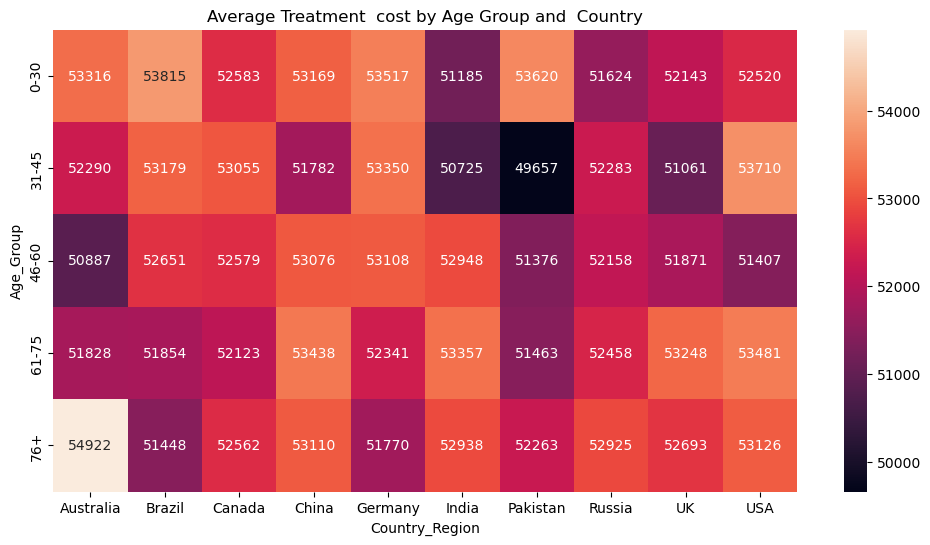

In [40]:
plt.figure(figsize=(12,6))
sns.heatmap(heatmap_data, annot=True, fmt=".0f")
plt.title("Average Treatment  cost by Age Group and  Country")
plt.show()

## Assess whether higher treatment cost is associated with longer survival

In [45]:
from scipy.stats import pearsonr, spearmanr
x = df["Treatment_Cost_USD"]
y = df["Survival_Years"]

In [46]:
# performing pearson correlation test
pearson_corr, pearson_p = pearsonr(x, y)
print(f"Pearson Correlation Coefficient: {pearson_corr}")
print(f"Pearson P-Value: {pearson_p}")

Pearson Correlation Coefficient: -0.00042940542830214955
Pearson P-Value: 0.9235082012963326


In [47]:
# performing spearman correlation test
spearman_corr, spearman_p = spearmanr(x, y)
print(f"Spearman Correlation Coefficient: {spearman_corr}")
print(f"Spearman P-Value: {spearman_p}")

Spearman Correlation Coefficient: -0.0004454737292549569
Spearman P-Value: 0.9206551702014918


In [48]:
alpha = 0.05
def interpret_corr(corr, p, method):
    if p < alpha:
        print(f"{method}, we reject the null hypothesis")
    else:
        print(f"{method}, we failed to reject null hypothesis")

interpret_corr(pearson_corr, pearson_p, "Pearson")
interpret_corr(spearman_corr, spearman_p, "Spearman")

Pearson, we failed to reject null hypothesis
Spearman, we failed to reject null hypothesis


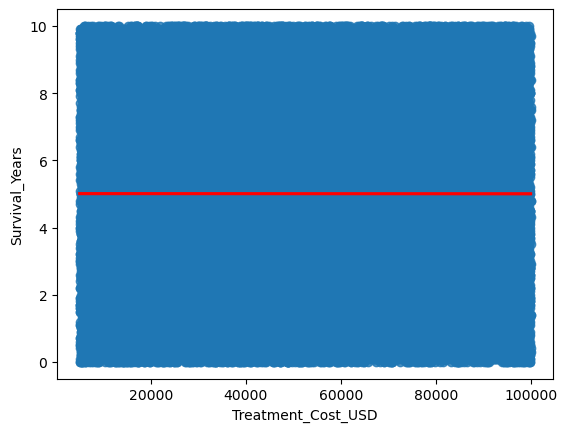

In [51]:
sns.regplot(x=x, y=y, line_kws={"color":"red"})
plt.show()

## Evaluate if higher cancer stages lead to greater treatment costs and reduced survival years

In [52]:
stage_order = ['Stage 0', 'Stage I', 'Stage II', 'Stage III', 'Stage IV']

In [53]:
grouped_stats = df.groupby("Cancer_Stage")[["Treatment_Cost_USD", "Survival_Years"]].mean().reset_index()

In [54]:
grouped_stats

,Cancer_Stage,Treatment_Cost_USD,Survival_Years
0,Stage 0,52572.589493,5.015199
1,Stage I,52674.079638,5.012990
2,Stage II,52082.841258,4.995170
3,Stage III,52708.197506,5.036311
4,Stage IV,52302.471041,4.972596


In [55]:
grouped_costs=[]
grouped_survival=[]


for  stage in stage_order:
    stage_data= df[df["Cancer_Stage"]==stage]
    cost= stage_data["Treatment_Cost_USD"]
    survival= stage_data["Survival_Years"]
    grouped_costs.append(cost)
    grouped_survival.append(survival)
    

In [56]:
len(grouped_costs)

5

In [59]:
# check for normaility
from scipy.stats import  shapiro, f_oneway
non_normal_cost=0
non_normal_survival=0

for i in range (len(stage_order)):
    cost_p= shapiro(grouped_costs[i]).pvalue
    surv_p= shapiro(grouped_survival[i]).pvalue 
    print(f" cost {cost_p} for group {i}")
    print(f"Survival {surv_p} for group {i}")
    if cost_p<0.05:
        non_normal_cost+=1
    if surv_p<0.05:
        non_normal_survival+=1

 cost 1.5471821061637387e-47 for group 0
Survival 1.6291039522109283e-47 for group 0
 cost 7.306523956950957e-48 for group 1
Survival 7.575551046259697e-48 for group 1
 cost 8.943579643043388e-48 for group 2
Survival 4.041659465829829e-48 for group 2
 cost 5.267270033022367e-48 for group 3
Survival 1.3648520457944784e-47 for group 3
 cost 1.5838640189581322e-47 for group 4
Survival 2.2992598289836786e-47 for group 4


In [60]:
print(non_normal_cost)
print(non_normal_survival)

5
5


In [61]:
from scipy.stats import kruskal
kusrkal_cost =kruskal(*grouped_costs)
kurkal_survival= kruskal(*grouped_survival)

p_cost= kusrkal_cost.pvalue
p_survival= kurkal_survival.pvalue

In [62]:
print(p_cost)
print(p_survival)

0.4254451689062656
0.6033078729984223


## Examine whether higher genetic risk amplifies the negative effects of smoking on cancer severity 

In [63]:
import statsmodels.formula.api as smf

model = smf.ols("Target_Severity_Score ~ Genetic_Risk*Smoking", data=data).fit()

model.summary2().tables[1].loc["Genetic_Risk:Smoking"]

Coef.      -0.000228
Std.Err.    0.000471
t          -0.484187
P>|t|       0.628255
[0.025     -0.001150
0.975]      0.000694
Name: Genetic_Risk:Smoking, dtype: float64